# TP4 - Redes convolucionales para clasificar lesiones de piel (ISIC)

**Dataset:** imágenes dermatoscópicas ISIC de 9 clases (~880 imágenes en la carpeta `data/Split_smol`, con una subcarpeta por clase dentro de `train/` y `val/`).

El **código ya está resuelto y probado**. Lo que se evalúa es **su análisis**. El cómputo lleva unos 15-20 minutos (medido en una CPU de 20 núcleos), y les queda la mayor parte de las 2 horas para interpretar resultados.

**Qué se trabaja en este TP:** análisis exploratorio, limpieza de duplicados y split, convoluciones, pooling y campo receptivo, comparación MLP vs. CNN, decisiones de arquitectura, resolución de entrada, data augmentation y evaluación final.
**Qué NO se repite** porque ya lo hicieron en los TP1 a TP3: búsqueda de hiperparámetros con Optuna, dropout/L2/BatchNorm como variables de estudio (la BatchNorm queda fija dentro del bloque convolucional), inicialización y logging con TensorBoard/MLflow.

**Cómo trabajar:** ejecuten de arriba hacia abajo, lean los outputs y completen las celdas **✏️** (observaciones de EDA, explicación del código convolucional y cuatro análisis). Las comparaciones usan **3 semillas** y reportan media ± desvío: una diferencia solo cuenta si supera ese ruido.

**Reglas metodológicas (las mismas de los TPs anteriores):**
- Las entradas van **normalizadas** (media y desvío por canal calculados **solo en train**).
- El **test se usa una sola vez**, en la sección 8. Todo lo demás se decide con validación.
- La augmentation se aplica **solo a train y después del split**.
- Las conclusiones tienen que **coincidir con los outputs** de su corrida.

## 0. Configuración
Si no tienen GPU, los valores por defecto funcionan en CPU. Si cambian alguna constante, **anótenlo en su análisis**.

In [1]:
import os, time, random, copy, hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import warnings; warnings.filterwarnings("ignore")

DATA_DIR    = "data/Split_smol"    # carpeta con train/ y val/ (una subcarpeta por clase)
SIZES       = [32, 64, 96]         # resoluciones de entrada que se van a comparar
SEEDS       = [0, 1, 2]            # semillas para medir ruido
MAX_EPOCHS  = 60                   # épocas máximas (con early stopping)
PATIENCE    = 10                   # épocas sin mejorar val_loss antes de cortar
BATCH       = 32
AUG_COPIES  = 2                    # copias aumentadas que se agregan a cada imagen de train
SEED_SPLIT  = 42                   # semilla del split (NO cambiarla entre corridas)
SEEDS_FINAL = [0, 1, 2, 3, 4]      # semillas de la evaluación final

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
print("Dispositivo:", device, "| torch", torch.__version__)

Dispositivo: cuda | torch 2.14.1+cu130


## 1. Análisis exploratorio (EDA)
Antes de modelar hay que mirar los datos: cuántas imágenes hay por clase, de qué tamaños son, cómo se ven y si hay algo raro (desbalance, resoluciones distintas por clase, **imágenes repetidas**). Acá todavía no se divide nada: se trabaja con todas las imágenes tal como vienen.

In [2]:
class_names = sorted(os.listdir(f"{DATA_DIR}/train")); NUM_CLASSES = len(class_names)
meta = []
for sp in ["train", "val"]:
    for ci, c in enumerate(class_names):
        for f in sorted(os.listdir(f"{DATA_DIR}/{sp}/{c}")):
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                p = f"{DATA_DIR}/{sp}/{c}/{f}"
                with Image.open(p) as im: w, h = im.size
                meta.append(dict(path=p, carpeta=sp, clase=c, y=ci, w=w, h=h, md5=hashlib.md5(open(p, "rb").read()).hexdigest()))
df = pd.DataFrame(meta); df["res"] = df["w"].astype(str) + "x" + df["h"].astype(str); df["aspecto"] = df["w"] / df["h"]
print(f"{len(df)} imágenes, {NUM_CLASSES} clases")

# Se cargan todas las imágenes una sola vez, ya redimensionadas a cuadrados, para todas las resoluciones
t0 = time.time(); RAW = {s: [] for s in SIZES}
for p in df["path"]:
    with Image.open(p) as im0:
        im = im0.convert("RGB")
        for s in SIZES: RAW[s].append(np.asarray(im.resize((s, s), Image.BILINEAR)))
X_U8 = {s: torch.from_numpy(np.stack(RAW[s])).permute(0, 3, 1, 2).contiguous() for s in SIZES}; del RAW
Y = torch.from_numpy(df["y"].values); labels = df["y"].values
print(f"Carga de imágenes: {time.time() - t0:.0f}s | tensor {tuple(X_U8[64].shape)} uint8")

878 imágenes, 9 clases
Carga de imágenes: 5s | tensor (878, 3, 64, 64) uint8


carpeta,train,val,All
clase,,,
Actinic keratosis,80,20,100
Atopic Dermatitis,81,21,102
Benign keratosis,80,20,100
Dermatofibroma,80,20,100
Melanocytic nevus,80,20,100
Melanoma,80,20,100
Squamous cell carcinoma,80,20,100
Tinea Ringworm Candidiasis,56,20,76
Vascular lesion,80,20,100


Resoluciones más frecuentes:


res,600x450,1024x768,294x222,1024x764,1022x767,767x576,919x802,1024x681
imágenes,400,135,102,74,21,12,6,5


Fracción de cada clase por resolución:


res,1022x767,1024x764,1024x768,294x222,600x450,otras
clase,,,,,,
Actinic keratosis,0.00,0.00,0.00,0.0,1.0,0.00
Atopic Dermatitis,0.00,0.00,0.00,1.0,0.0,0.00
Benign keratosis,0.00,0.74,0.00,0.0,0.0,0.26
Dermatofibroma,0.00,0.00,0.00,0.0,1.0,0.00
Melanocytic nevus,0.18,0.00,0.79,0.0,0.0,0.03
Melanoma,0.03,0.00,0.56,0.0,0.0,0.41
Squamous cell carcinoma,0.00,0.00,0.00,0.0,1.0,0.00
Tinea Ringworm Candidiasis,0.00,0.00,0.00,0.0,0.0,1.00
Vascular lesion,0.00,0.00,0.00,0.0,1.0,0.00


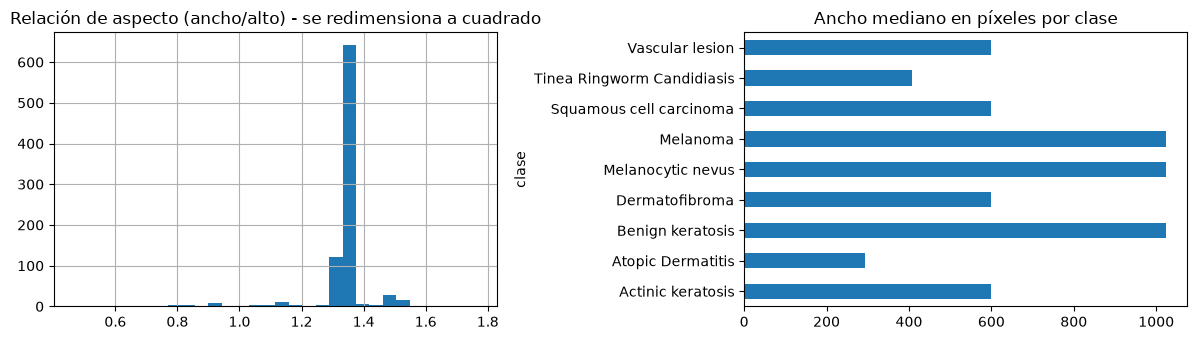

In [3]:
# 1.1 Clases y carpeta de origen
display(pd.crosstab(df["clase"], df["carpeta"], margins=True))
# 1.2 Resoluciones: ¿son todas iguales? ¿dependen de la clase?
print("Resoluciones más frecuentes:"); display(df["res"].value_counts().head(8).to_frame("imágenes").T)
top = df["res"].value_counts().head(5).index
ct = pd.crosstab(df["clase"], df["res"].where(df["res"].isin(top), "otras"), normalize="index").round(2)
print("Fracción de cada clase por resolución:"); display(ct)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df["aspecto"].hist(bins=30, ax=ax[0]); ax[0].set_title("Relación de aspecto (ancho/alto) - se redimensiona a cuadrado")
(df.groupby("clase")["w"].median()).plot.barh(ax=ax[1]); ax[1].set_title("Ancho mediano en píxeles por clase"); plt.tight_layout(); plt.show()

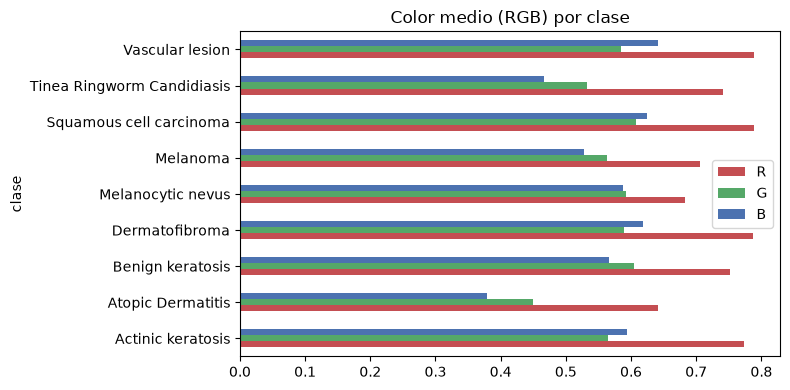

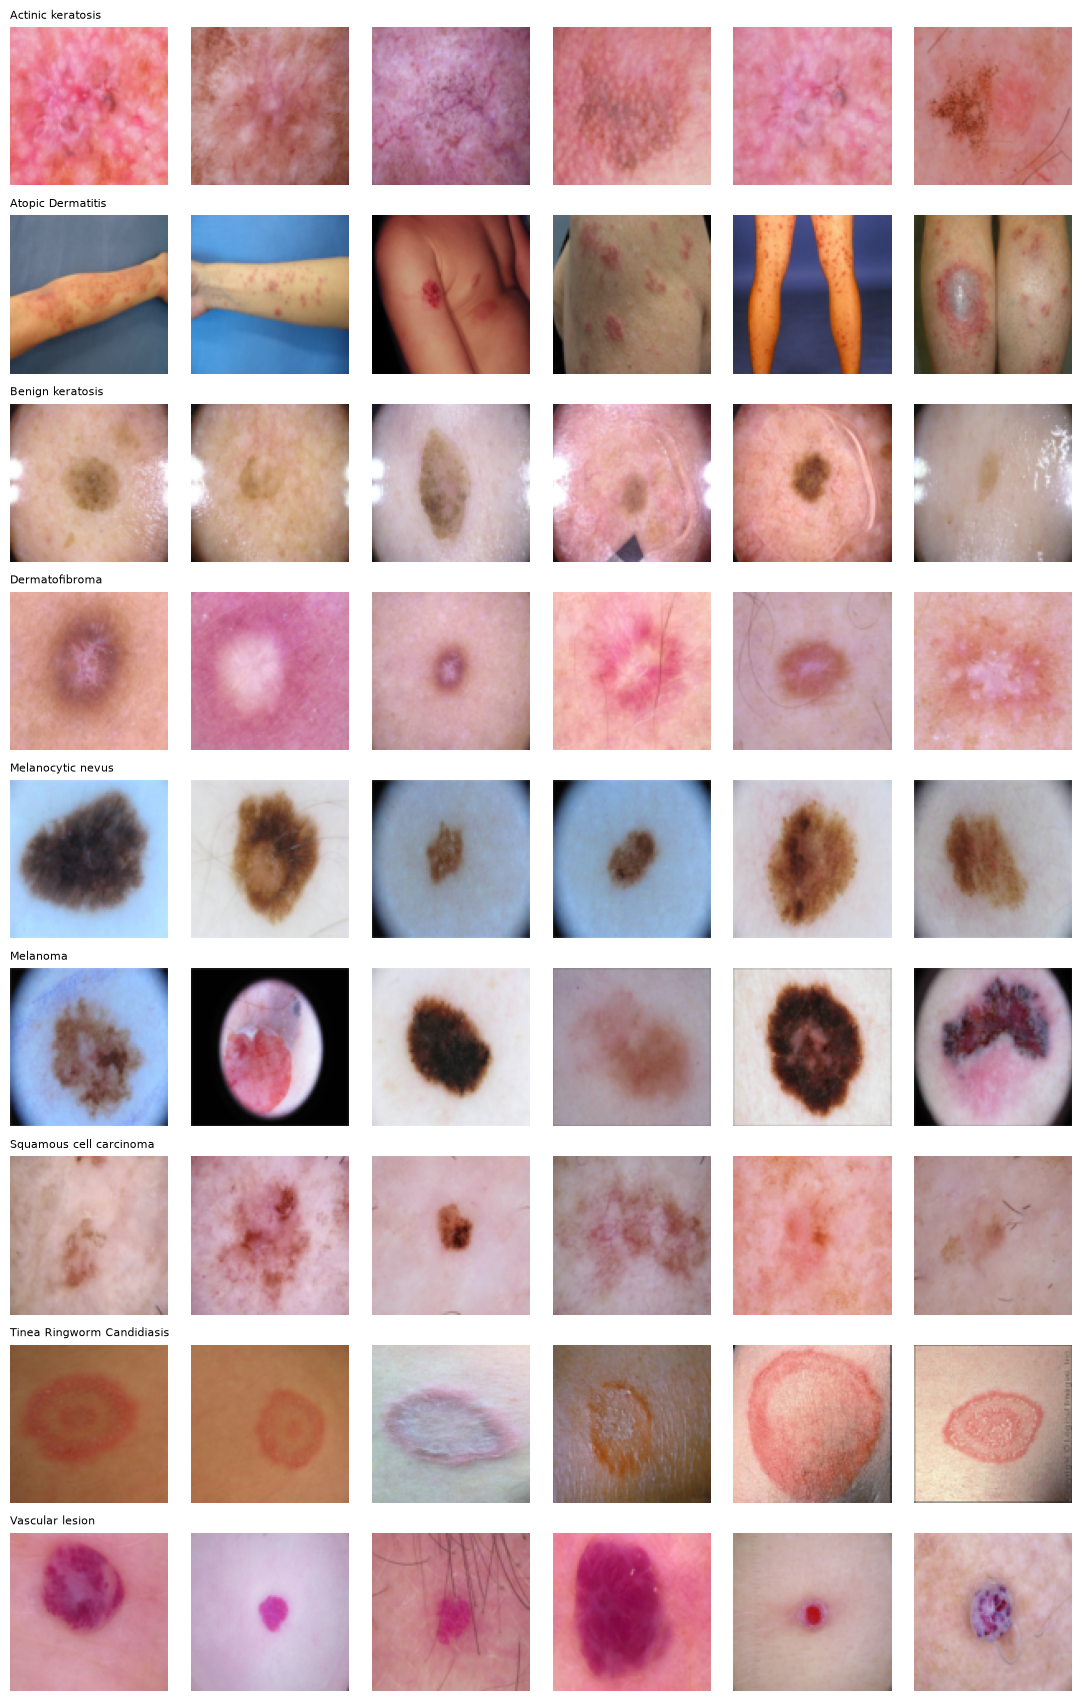

In [4]:
# 1.3 Color medio por clase y ejemplos
mean_rgb = pd.DataFrame(X_U8[32].float().mean((2, 3)).numpy() / 255, columns=["R", "G", "B"]); mean_rgb["clase"] = df["clase"].values
mean_rgb.groupby("clase").mean().plot.barh(color=["#c44e52", "#55a868", "#4c72b0"], figsize=(8, 4), title="Color medio (RGB) por clase"); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(11, 1.9 * NUM_CLASSES))
for ci in range(NUM_CLASSES):
    ids = np.where(labels == ci)[0][:6]
    for j, i in enumerate(ids): axes[ci, j].imshow(X_U8[96][i].permute(1, 2, 0)); axes[ci, j].axis("off")
    axes[ci, 0].set_title(class_names[ci], fontsize=8, loc="left")
plt.tight_layout(); plt.show()

### 1.4 Imágenes duplicadas
El dataset viene con una partición `train/`/`val/` propia. Si una misma imagen está en las dos carpetas, la validación **no mide generalización** (el modelo ya vio esas imágenes). Se buscan duplicados **exactos** (mismo hash MD5 del archivo) y se verifica con un hash perceptual (diferencias entre píxeles vecinos de una miniatura) que no queden **casi-duplicados** (recortes o recompresiones).

In [5]:
g = df.groupby("md5")
dup_groups = [idx for _, idx in g.groups.items() if len(idx) > 1]
cross = [idx for idx in dup_groups if df.loc[idx, "carpeta"].nunique() > 1]
print(f"Grupos de imágenes idénticas: {len(dup_groups)} (de los cuales {len(cross)} están repetidos entre train y val)")
print("Por clase:", df.loc[[idx[0] for idx in dup_groups], "clase"].value_counts().to_dict())
print("Conflictos de etiqueta (misma imagen con clases distintas):", sum(df.loc[idx, "y"].nunique() > 1 for idx in dup_groups))

# hash perceptual: miniatura gris 16x17, bit = pixel > vecino derecho (256 bits); distancia de Hamming
gray = X_U8[32].float().mean(1, keepdim=True)
th_ = F.interpolate(gray, size=(16, 17), mode="area")
H = (th_[..., 1:] > th_[..., :-1]).flatten(1).numpy()
near = []
for i in range(len(H)):
    d = (H[i] != H[i + 1:]).sum(1)
    near += [(i, i + 1 + j) for j in np.where(d <= 8)[0]]
near_not_exact = [(i, j) for i, j in near if df.loc[i, "md5"] != df.loc[j, "md5"]]
print(f"Pares con hash perceptual casi igual (<=8 bits de 256): {len(near)} | de ellos NO idénticos por MD5: {len(near_not_exact)}")

Grupos de imágenes idénticas: 34 (de los cuales 33 están repetidos entre train y val)
Por clase: {'Atopic Dermatitis': 22, 'Tinea Ringworm Candidiasis': 12}
Conflictos de etiqueta (misma imagen con clases distintas): 0
Pares con hash perceptual casi igual (<=8 bits de 256): 34 | de ellos NO idénticos por MD5: 0


In [6]:
# Partición original después de eliminar duplicados (se conserva la primera copia de cada imagen)
dedup = df.drop_duplicates("md5")
display(pd.crosstab(dedup["clase"], dedup["carpeta"], margins=True))

carpeta,train,val,All
clase,,,
Actinic keratosis,80,20,100
Atopic Dermatitis,80,0,80
Benign keratosis,80,20,100
Dermatofibroma,80,20,100
Melanocytic nevus,80,20,100
Melanoma,80,20,100
Squamous cell carcinoma,80,20,100
Tinea Ringworm Candidiasis,56,8,64
Vascular lesion,80,20,100


### ✏️ TUS OBSERVACIONES DEL EDA
Respondan en pocas líneas, con los números de los outputs de arriba:
1. ¿Qué tan desbalanceado está el dataset? ¿Qué cambia respecto de la partición original `train`/`val`?
2. ¿Hay clases que se distinguen por resolución, relación de aspecto o color de fondo? ¿Qué riesgo tiene eso para un modelo que ve las imágenes redimensionadas?
3. ¿Qué duplicados encontraron, en qué clases y por qué importan para la validación? ¿Qué hubiera pasado con la `val_acc` si no los eliminaran?

1. El dataset original tiene 878 imágenes, donde 8 clases tienen ≈ 100 imágenes cada una y Tinea tiene 76, por lo que solo está levemente desbalanceado. El ratio es 100/76 ≈ 1.3. Al eliminar las imágenes repetidas, los 34 duplicados están todos en Atopic (22) y Tinea (12), y al eliminarlos quedan 80 y 64, por lo que el desbalance real es de ≈ 1.6.
Pero el mayor problema es que al eliminar las repeticiones, Atopic Dermatitis se queda sin imágenes de validación y Tinea pasa de 20 a 8 en val. Por eso es importante volver a dividir y armar una nueva partición.

2. Hay clases que se distinguen por resolución, ya que Atopic Dermatitis es 100 % 294×222 y Tinea 100 % de resoluciones atípicas (~400 px de ancho), Actinic keratosis, Dermatofibroma, SCC y Vascular son 100 % 600×450, y Nevus, Melanoma y Benign keratosis son dermatoscopías de ~1024 px. En cambio, la relación de aspecto es casi siempre de 4:3, por lo que no hay mucha discriminación por este parámetro. Y por color, todas las clases están dominadas por el rojo (que corresponde a la piel), pero la diferencia está principalmente en la relación entre G y B y en el brillo general.
El riesgo es que el modelo aprenda a reconocer la fuente de la imagen en vez de la lesión, porque al redimensionar las imágenes, la diferencia en la resolución original va a causar diferencias en la nitidez, el ruido y la compresión, y además sobreviven el fondo, la viñeta y los reflejos. Esto puede generar un atajo que infle el accuracy (sobre todo en Atopic y Tinea) sin generalizar a imágenes de otra fuente, y que no sirve para distinguir clases de la misma fuente, como nevus y melanoma.

3. Se encontraron 34 grupos de imágenes idénticas, 22 en Atopic Dermatitis y 12 en Tinea. 33 de los 34 tienen una copia en `train` y otra en `val`. Eso significa que las 21 imágenes de val de Atopic y 12 de las 20 de Tinea ya estaban en train: 33 de las 181 imágenes de val (18 %) eran imágenes que el modelo ve al entrenar.
La validación debería medir generalización sobre imágenes nuevas, pero con duplicados mide memorización. La val_acc habría quedado inflada, porque el 18 % de val serían imágenes que el modelo ya memorizó. Además, el early stopping y la elección de arquitectura se habrían decidido con una métrica que premia memorizar.

## 2. Eliminación de duplicados y split estratificado
- Se **elimina una copia de cada imagen duplicada** (se conserva una sola por grupo de MD5).
- Se juntan **todas** las imágenes que quedan (la partición original no sirve: tenía repetidas y no tenía test) y se hace un split **estratificado 60/20/20** con semilla fija. El test no se toca hasta la sección 8.
- Se calcula la **normalización** (media y desvío por canal) **solo con train**.

In [7]:
keep = df.groupby("md5").head(1).index.values            # una imagen por hash
print(f"Imágenes totales: {len(df)} -> sin duplicados: {len(keep)} (se eliminaron {len(df) - len(keep)})")
idx_tr, idx_tmp = train_test_split(keep, test_size=0.4, stratify=labels[keep], random_state=SEED_SPLIT)
idx_va, idx_te  = train_test_split(idx_tmp, test_size=0.5, stratify=labels[idx_tmp], random_state=SEED_SPLIT)
print(f"train {len(idx_tr)} | val {len(idx_va)} | test {len(idx_te)}")
print(pd.DataFrame({"train": pd.Series(df.loc[idx_tr, "clase"]).value_counts(), "val": pd.Series(df.loc[idx_va, "clase"]).value_counts(),
                    "test": pd.Series(df.loc[idx_te, "clase"]).value_counts()}).to_string())
assert not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_va, "md5"])) and not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_te, "md5"])) and not (set(df.loc[idx_va, "md5"]) & set(df.loc[idx_te, "md5"]))
STATS = {}
for s in SIZES:
    xt = X_U8[s][idx_tr].float() / 255
    STATS[s] = (xt.mean((0, 2, 3)).view(1, 3, 1, 1), xt.std((0, 2, 3)).view(1, 3, 1, 1))
print("mean/std por canal (64px, solo train):", STATS[64][0].flatten().numpy().round(3), STATS[64][1].flatten().numpy().round(3))

Imágenes totales: 878 -> sin duplicados: 844 (se eliminaron 34)
train 506 | val 169 | test 169
                            train  val  test
clase                                       
Actinic keratosis              60   20    20
Atopic Dermatitis              48   16    16
Benign keratosis               60   20    20
Dermatofibroma                 60   20    20
Melanocytic nevus              60   20    20
Melanoma                       60   20    20
Squamous cell carcinoma        60   20    20
Tinea Ringworm Candidiasis     38   13    13
Vascular lesion                60   20    20
mean/std por canal (64px, solo train): [0.743 0.572 0.565] [0.162 0.164 0.186]


## 3. Data augmentation a mano (solo sobre train, después del split)
No se usa ninguna librería de augmentation: las transformaciones están escritas con operaciones de tensores. Cada imagen de **train** se complementa con `AUG_COPIES` copias transformadas **ya generadas** (se calculan una vez, después del split, así que ninguna copia de una imagen de val/test puede filtrarse a train). Val y test **nunca** se aumentan.

Transformaciones disponibles: flips horizontal/vertical, rotaciones de 90° y brillo/contraste aleatorios. Las lesiones dermatoscópicas no tienen orientación privilegiada, pero el **color** es información diagnóstica.

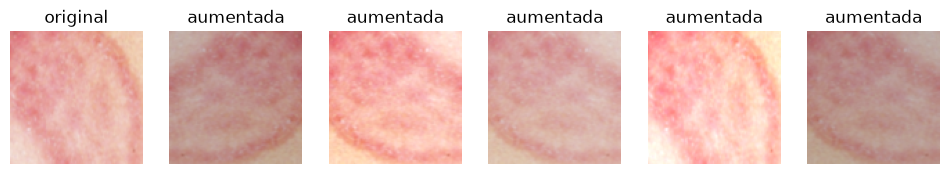

In [8]:
AUGS = {"ninguna": {}, "flips": dict(hflip=True, vflip=True),
        "flips+rot90": dict(hflip=True, vflip=True, rot90=True),
        "flips+rot90+color": dict(hflip=True, vflip=True, rot90=True, color=0.2)}

def augment(x, a):
    # x: tensor float [B,3,H,W] en [0,1]. Cada imagen recibe sus propias transformaciones al azar.
    B = x.shape[0]; x = x.clone()
    if a.get("hflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(3)
    if a.get("vflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(2)
    if a.get("rot90"):
        k = torch.randint(0, 4, (B,))
        for kv in (1, 2, 3):
            m = k == kv
            if m.any(): x[m] = torch.rot90(x[m], kv, (2, 3))
    if a.get("color"):
        c = a["color"]
        bri = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c; con = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c
        mu = x.mean((1, 2, 3), keepdim=True); x = ((x - mu) * con + mu) * bri
    return x.clamp(0, 1)

TRAIN_SETS = {}
def train_set(size, aug_name):
    # originales de train + AUG_COPIES copias aumentadas de cada una (generadas una vez, con semilla fija)
    key = (size, aug_name)
    if key not in TRAIN_SETS:
        x0, y0 = X_U8[size][idx_tr], Y[idx_tr]
        if aug_name == "ninguna": TRAIN_SETS[key] = (x0, y0)
        else:
            set_seed(1234); xs, ys = [x0], [y0]
            for _ in range(AUG_COPIES): xs.append((augment(x0.float() / 255, AUGS[aug_name]) * 255).round().to(torch.uint8)); ys.append(y0)
            TRAIN_SETS[key] = (torch.cat(xs), torch.cat(ys))
    return TRAIN_SETS[key]

# Vista de una imagen y sus versiones aumentadas
i0 = idx_tr[0]; base = X_U8[96][i0:i0 + 1].float() / 255; set_seed(3)
fig, ax = plt.subplots(1, 6, figsize=(12, 2.3)); ax[0].imshow(base[0].permute(1, 2, 0)); ax[0].set_title("original")
for k in range(1, 6): ax[k].imshow(augment(base, AUGS["flips+rot90+color"])[0].permute(1, 2, 0)); ax[k].set_title("aumentada")
for a in ax: a.axis("off")
plt.show()

## 4. Modelos y entrenamiento
- **`MLP`**: la referencia (Flatten + 2 capas ocultas).
- **`CNN`**: `n_blocks` bloques `Conv2d → BatchNorm → ReLU → MaxPool(2)` con `filters·2^b` canales, y una cabeza `Flatten → Linear(128) → ReLU → Dropout → Linear(clases)`.
- **`rf_full(...)`** calcula el **campo receptivo** teórico de la última capa convolucional.
- **Entrenamiento**: Adam, early stopping sobre `val_loss` restaurando el mejor estado, tiempo por época medido.

In [9]:
class MLP(nn.Module):
    def __init__(self, size, num_classes=NUM_CLASSES):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(3 * size * size, 512), nn.ReLU(),
                                 nn.Linear(512, 128), nn.ReLU(), nn.Linear(128, num_classes))
    def forward(self, x): return self.net(x)

class CNN(nn.Module):
    def __init__(self, size, n_blocks=3, filters=16, kernel=3, use_bn=True, dropout=0.2, num_classes=NUM_CLASSES):
        super().__init__()
        layers, cin = [], 3
        for b in range(n_blocks):
            cout = filters * 2 ** b
            layers += [nn.Conv2d(cin, cout, kernel, padding=kernel // 2, bias=not use_bn)]
            if use_bn: layers += [nn.BatchNorm2d(cout)]
            layers += [nn.ReLU(), nn.MaxPool2d(2)]
            cin = cout
        self.features = nn.Sequential(*layers)
        fs = size // 2 ** n_blocks                       # lado del mapa de activación después de los n_blocks pooling
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(cin * fs * fs, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, num_classes))
    def forward(self, x): return self.head(self.features(x))

def rf_full(n_blocks, kernel):
    # campo receptivo de la última conv: cada conv suma (k-1)*salto; cada maxpool(2) suma 1*salto y duplica el salto
    r, j = 1, 1
    for b in range(n_blocks):
        r += (kernel - 1) * j
        if b < n_blocks - 1: r += 1 * j; j *= 2
    return r
def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

def norm_batch(x_u8, size):
    mu, sd = STATS[size]; return ((x_u8.float() / 255 - mu) / sd).to(device)

def get_eval_batch(size, ids, shift=0):
    x = X_U8[size][ids].float() / 255
    if shift:   # traslación circular aleatoria (solo para medir robustez a traslaciones)
        x = torch.stack([torch.roll(xi, shifts=(int(np.random.randint(-shift, shift + 1)), int(np.random.randint(-shift, shift + 1))), dims=(1, 2)) for xi in x])
    mu, sd = STATS[size]; return ((x - mu) / sd).to(device), Y[ids].to(device)

@torch.no_grad()
def evaluate(model, ids, size, shift=0):
    model.eval(); L, P = 0.0, []
    for i in range(0, len(ids), 256):
        xb, yb = get_eval_batch(size, ids[i:i + 256], shift)
        out = model(xb); L += F.cross_entropy(out, yb, reduction="sum").item(); P.append(out.argmax(1).cpu())
    P = torch.cat(P).numpy()
    return L / len(ids), accuracy_score(labels[ids], P), P

def make_model(cfg):
    if cfg["model"] == "mlp": return MLP(cfg["size"])
    return CNN(cfg["size"], cfg["n_blocks"], cfg["filters"], cfg["kernel"], cfg.get("use_bn", True), cfg["dropout"])

def fit(cfg, seed):
    set_seed(seed); model = make_model(cfg).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"]); size = cfg["size"]
    Xtr, Ytr = train_set(size, cfg["aug"])
    h = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[], epoch_time=[])
    best, best_ep, best_state, bad = 1e9, 0, None, 0
    for ep in range(MAX_EPOCHS):
        t0 = time.time(); model.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(perm), BATCH):
            ids = perm[i:i + BATCH]
            if len(ids) < 2: continue
            opt.zero_grad(); F.cross_entropy(model(norm_batch(Xtr[ids], size)), Ytr[ids].to(device)).backward(); opt.step()
        if device.type == "cuda": torch.cuda.synchronize()
        h["epoch_time"].append(time.time() - t0)
        trl, tra, _ = evaluate(model, idx_tr, size)       # train ORIGINAL en modo eval (sin dropout ni copias aumentadas)
        vl, va, _ = evaluate(model, idx_va, size)
        h["train_loss"].append(trl); h["train_acc"].append(tra); h["val_loss"].append(vl); h["val_acc"].append(va)
        if vl < best - 1e-4: best, best_ep, best_state, bad = vl, ep, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    h.update(best_epoch=best_ep + 1, n_epochs=len(h["val_loss"]), n_params=n_params(model))
    return model, h

def run(cfg, seeds=SEEDS):
    # entrena la config con varias semillas y resume (media ± desvío)
    ms, hs = [], []
    for s in seeds:
        m, h = fit(cfg, s); ms.append(m); hs.append(h)
    be = [h["best_epoch"] - 1 for h in hs]
    va = [h["val_acc"][e] for h, e in zip(hs, be)]
    r = dict(val_acc=np.mean(va), val_acc_std=np.std(va), train_acc=np.mean([h["train_acc"][e] for h, e in zip(hs, be)]),
             val_loss=np.mean([min(h["val_loss"]) for h in hs]), best_epoch=np.mean([h["best_epoch"] for h in hs]),
             t_epoca_s=np.mean([np.mean(h["epoch_time"]) for h in hs]), t_total_s=np.mean([sum(h["epoch_time"]) for h in hs]), params=hs[0]["n_params"])
    r["brecha"] = r["train_acc"] - r["val_acc"]
    return r, ms, hs

BASE = dict(model="cnn", size=64, n_blocks=3, filters=16, kernel=3, dropout=0.2, lr=3e-3, aug="ninguna")
print("Parámetros CNN base (64px):", n_params(CNN(64)), "| MLP (64px):", n_params(MLP(64)), "| campo receptivo CNN base:", rf_full(3, 3), "px")

Parámetros CNN base (64px): 549273 | MLP (64px): 6358793 | campo receptivo CNN base: 18 px


### 4.1 Cómo se transforma una imagen dentro de la CNN
La tabla muestra, capa por capa, la **forma de la salida** `(canales, alto, ancho)` y la **cantidad de parámetros** de la CNN base con una imagen de 64×64.

In [10]:
def trace(model, size):
    model.eval(); x = torch.zeros(1, 3, size, size); rows = []
    for i, l in enumerate(list(model.features) + list(model.head)):
        x = l(x); rows.append(dict(capa=i, tipo=l.__class__.__name__, detalle=str(l)[:46], salida=tuple(x.shape[1:]), params=sum(p.numel() for p in l.parameters())))
    return pd.DataFrame(rows)
tr = trace(CNN(64), 64); display(tr); print("Total de parámetros:", tr["params"].sum())

,capa,tipo,detalle,salida,params
0,0,Conv2d,"Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1","(16, 64, 64)",432
1,1,BatchNorm2d,"BatchNorm2d(16, eps=1e-05, momentum=0.1, affin","(16, 64, 64)",32
2,2,ReLU,ReLU(),"(16, 64, 64)",0
3,3,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(16, 32, 32)",0
4,4,Conv2d,"Conv2d(16, 32, kernel_size=(3, 3), stride=(1,","(32, 32, 32)",4608
5,5,BatchNorm2d,"BatchNorm2d(32, eps=1e-05, momentum=0.1, affin","(32, 32, 32)",64
6,6,ReLU,ReLU(),"(32, 32, 32)",0
7,7,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(32, 16, 16)",0
8,8,Conv2d,"Conv2d(32, 64, kernel_size=(3, 3), stride=(1,","(64, 16, 16)",18432
9,9,BatchNorm2d,"BatchNorm2d(64, eps=1e-05, momentum=0.1, affin","(64, 16, 16)",128


Total de parámetros: 549273


### ✏️ EXPLICÁ EL CÓDIGO CONVOLUCIONAL
Con la clase `CNN` y la tabla de arriba, expliquen con sus palabras (y verificando con los números de la tabla):
1. **`padding=kernel // 2`**: ¿qué pasa con el alto y el ancho al aplicar la convolución? ¿Qué pasaría con `padding=0`? ¿Cómo se ve en la tabla?
2. **`MaxPool2d(2)`**: ¿qué hace con la forma de salida y qué información conserva? ¿Qué relación tiene con `fs = size // 2 ** n_blocks`?
3. **Parámetros:** calculen a mano cuántos parámetros tiene la segunda `Conv2d` (16 → 32 canales, kernel 3) y la primera `Linear` de la cabeza. Verifiquen con la tabla. ¿Cuál de las dos domina el total y por qué?
4. **`bias=not use_bn`:** ¿por qué la convolución no necesita sesgo cuando le sigue una BatchNorm?
5. **`filters * 2 ** b`:** ¿por qué se duplican los canales mientras se reduce la resolución a la mitad?
6. **`rf_full`:** reproduzcan a mano el campo receptivo de 18 px para 3 bloques con kernel 3 y expliquen qué significa ese número respecto de una imagen de 64 px.

1. **`padding=kernel // 2`:** con kernel 3 el padding es 1, y el tamaño de salida de la convolución es H_out = H + 2p − k + 1 = 64 + 2 − 3 + 1 = 64, es decir, la convolución mantiene el alto y el ancho. En la tabla se ve en la capa 0: la entrada (3, 64, 64) pasa a (16, 64, 64), y lo mismo en las capas 4 y 8, donde solo cambian los canales. Con `padding=0`, cada convolución le restaría k − 1 = 2 píxeles al lado (64 → 62), los bordes se perderían en cada bloque y los tamaños dejarían de ser potencias de 2, por lo que `fs = size // 2 ** n_blocks` ya no coincidiría con el tamaño real del mapa.

2. **`MaxPool2d(2)`:** divide por 2 el alto y el ancho sin cambiar la cantidad de canales: (16, 64, 64) → (16, 32, 32) en la capa 3, (32, 32, 32) → (32, 16, 16) en la capa 7 y (64, 16, 16) → (64, 8, 8) en la capa 11. De cada ventana de 2×2 conserva solo el valor máximo, es decir, la respuesta más fuerte del filtro en esa zona, y pierde la posición exacta dentro de la ventana, lo que da una pequeña invarianza a traslaciones. No tiene parámetros (0 en la tabla). Como hay un pooling por bloque, con 3 bloques el lado se reduce 2³ = 8 veces: `fs = 64 // 8 = 8`, que coincide con el (64, 8, 8) de la capa 11.

3. **Parámetros:** la segunda `Conv2d` tiene un filtro de 3×3 por cada canal de entrada y de salida: 3 · 3 · 16 · 32 = 4608 parámetros, sin sesgo porque `bias=False`. Coincide con la capa 4. La primera `Linear` recibe el mapa aplanado de 64 · 8 · 8 = 4096 valores y tiene 128 neuronas: 4096 · 128 + 128 = 524 416 parámetros, que coincide con la capa 13. La `Linear` domina el total: es el 95.5 % de los 549 273 parámetros. La convolución comparte los mismos pesos en todas las posiciones de la imagen, así que su costo depende solo del kernel y de los canales, mientras que la `Linear` tiene un peso distinto para cada posición de cada canal hacia cada neurona.

4. **`bias=not use_bn`:** la BatchNorm resta la media del batch en cada canal, así que cualquier sesgo constante que sume la convolución se cancela. Además, la BatchNorm tiene su propio desplazamiento aprendible (β), que cumple la función del sesgo. Por eso el sesgo de la convolución sería redundante, y la BatchNorm agrega solo 2 parámetros por canal (32, 64 y 128 en la tabla).

5. **`filters * 2 ** b`:** los canales se duplican en cada bloque (16 → 32 → 64) mientras el pooling divide la resolución a la mitad (64 → 32 → 16 → 8). Cada pooling reduce la cantidad de posiciones a la cuarta parte, y al duplicar los canales se compensa parte de esa pérdida de capacidad de representación. Además, las capas más profundas detectan patrones más abstractos y variados (combinaciones de bordes y texturas), que necesitan más filtros, y como trabajan sobre mapas más chicos, agregar canales no las encarece demasiado.

6. **`rf_full`:** el campo receptivo r empieza en 1, con salto j = 1. En cada bloque, la convolución suma (k − 1) · j, y el pooling suma 1 · j y duplica el salto:
   - Bloque 1: conv → r = 1 + 2 · 1 = 3; pool → r = 3 + 1 = 4, j = 2.
   - Bloque 2: conv → r = 4 + 2 · 2 = 8; pool → r = 8 + 2 = 10, j = 4.
   - Bloque 3: conv → r = 10 + 2 · 4 = 18.

   Cada neurona de la última convolución "ve" un parche de 18×18 píxeles de la imagen original, el 28 % del lado de una imagen de 64 px. Puede detectar bordes y texturas locales, pero no la lesión entera ni su forma global; esa información la integra recién la capa `Linear` de la cabeza, que recibe todas las posiciones del mapa.

### 4.2 Chequeo rápido: el modelo aprende
Se entrena la CNN base con una semilla y se grafican curvas. Sirve para verificar que el pipeline funciona antes de correr los experimentos.

mejor época 10 | val_acc 0.615 | train_acc 0.820 | 0.07 s/época | total 4s


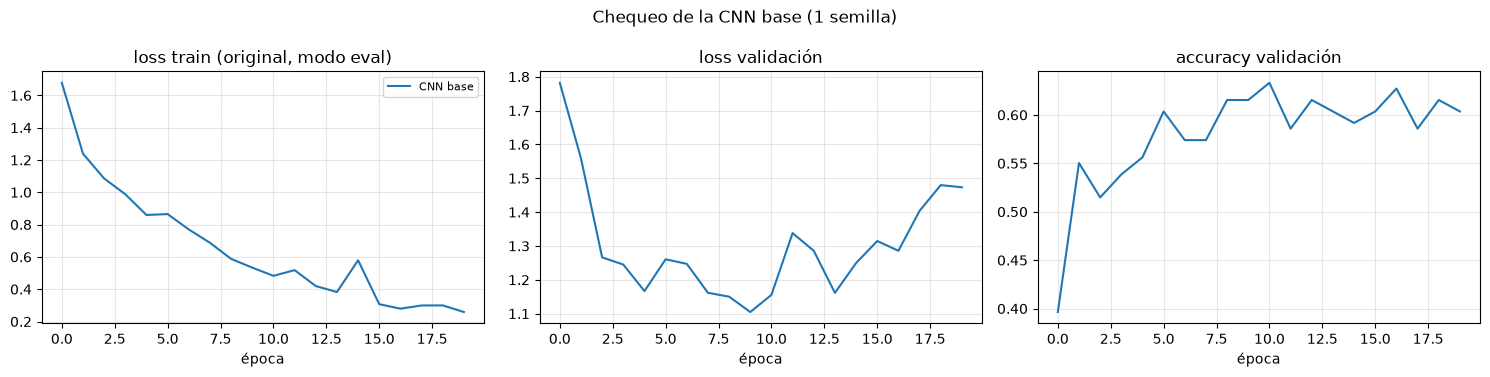

In [11]:
def plot_curves(hists, title):
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    for name, h in hists.items():
        ax[0].plot(h["train_loss"], label=name); ax[1].plot(h["val_loss"], label=name); ax[2].plot(h["val_acc"], label=name)
    for a, t in zip(ax, ["loss train (original, modo eval)", "loss validación", "accuracy validación"]): a.set_title(t); a.set_xlabel("época"); a.grid(alpha=.3)
    ax[0].legend(fontsize=8); fig.suptitle(title); plt.tight_layout(); plt.show()
t0 = time.time(); _, h = fit(BASE, 0)
print(f"mejor época {h['best_epoch']} | val_acc {h['val_acc'][h['best_epoch']-1]:.3f} | train_acc {h['train_acc'][h['best_epoch']-1]:.3f} | {np.mean(h['epoch_time']):.2f} s/época | total {time.time()-t0:.0f}s")
plot_curves({"CNN base": h}, "Chequeo de la CNN base (1 semilla)")

## 5. De la MLP a la CNN
Misma resolución, mismo split, mismo criterio de parada, 3 semillas. Además de val_acc se mide:
- **Parámetros y tiempo por época.**
- **Robustez a traslaciones**: se evalúa el modelo ya entrenado sobre validación con imágenes **trasladadas** al azar hasta ±`SHIFT` px (la convolución es equivariante a traslaciones y con pooling aproximadamente invariante; la MLP no tiene esa propiedad).

,modelo,params,val_acc,std,train_acc,brecha,mejor_epoca,t_epoca_s,val_acc_trasladada,caida_por_traslacion
0,MLP 32px,1640201,0.4970,0.0097,0.6943,0.1973,4.0000,0.0218,0.4135,0.0835
1,MLP 64px,6358793,0.4990,0.0311,0.6574,0.1584,5.6667,0.0300,0.4260,0.0730
2,CNN 32px,156057,0.6272,0.0193,0.8116,0.1844,8.6667,0.0394,0.5588,0.0684
3,CNN 64px,549273,0.6134,0.0438,0.7866,0.1731,11.0000,0.0422,0.5542,0.0592


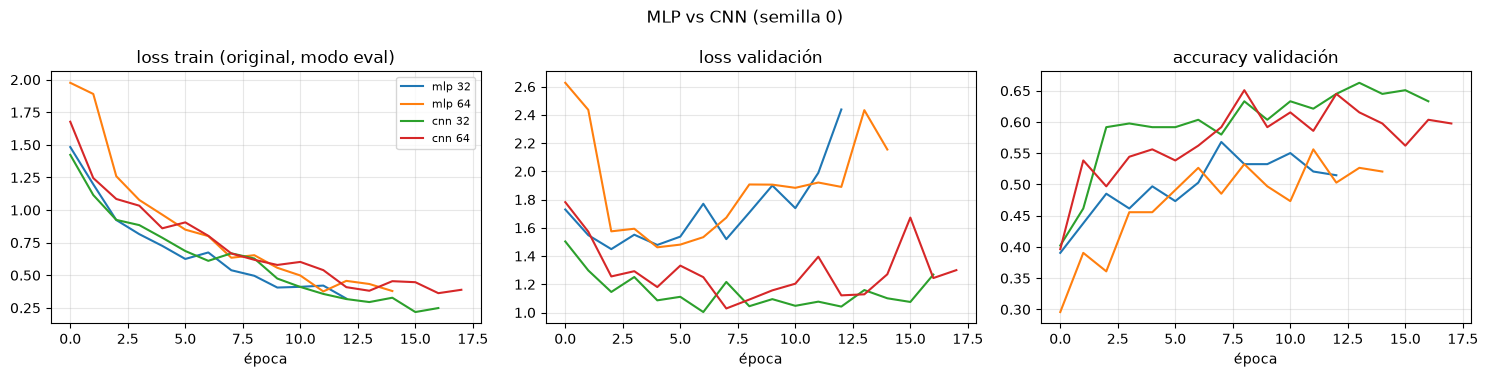

Referencia: azar = 0.111 | error estándar binomial de un accuracy ~0.5 con 169 imágenes de val = 0.038


In [12]:
SHIFT = {32: 4, 64: 8}
rows, store = [], {}
for model_name, size in [("mlp", 32), ("mlp", 64), ("cnn", 32), ("cnn", 64)]:
    cfg = {**BASE, "model": model_name, "size": size}
    r, ms, hs = run(cfg)
    clean = [evaluate(m, idx_va, size)[1] for m in ms]; shifted = [np.mean([evaluate(m, idx_va, size, shift=SHIFT[size])[1] for _ in range(3)]) for m in ms]
    rows.append(dict(modelo=f"{model_name.upper()} {size}px", params=r["params"], val_acc=r["val_acc"], std=r["val_acc_std"], train_acc=r["train_acc"],
                     brecha=r["brecha"], mejor_epoca=r["best_epoch"], t_epoca_s=r["t_epoca_s"],
                     val_acc_trasladada=np.mean(shifted), caida_por_traslacion=np.mean(clean) - np.mean(shifted)))
    store[f"{model_name} {size}"] = hs[0]
display(pd.DataFrame(rows).round(4))
plot_curves(store, "MLP vs CNN (semilla 0)")
print(f"Referencia: azar = {1/NUM_CLASSES:.3f} | error estándar binomial de un accuracy ~0.5 con {len(idx_va)} imágenes de val = {np.sqrt(.25/len(idx_va)):.3f}")

### ✏️ TU ANÁLISIS 1 - De la MLP a la CNN
1. Compará MLP y CNN en **parámetros, val_acc (± desvío), brecha train-val, tiempo por época y época de convergencia**. ¿La diferencia de val_acc supera el ruido entre semillas y el error estándar de la validación?
2. ¿Por qué la MLP necesita tantos más parámetros? Calculá a mano cuántos parámetros tiene la primera capa de la MLP a 32 y a 64 px y explicá qué pasaría a 224 px. ¿Qué propiedades de la convolución (pesos compartidos, conectividad local) cambian ese número?
3. Mirá la **caída por traslación**: ¿cuál de los dos modelos se degrada menos y por qué? ¿Es coherente con la teoría de equivarianza/invarianza, o el ruido no permite concluir?
4. ¿Qué rol cumple la normalización de entrada acá (mencionen cómo se calculó) y qué esperarían si no se hiciera?

1. **Comparación entre MLP y CNN**

La CNN obtiene mejores resultados: 0.627 ± 0.019 (32 px) y 0.613 ± 0.044 (64 px) de val_acc, contra 0.497 ± 0.010 y 0.499 ± 0.031 de la MLP. Además, usa unas 11 veces menos parámetros (549 273 contra 6 358 793 en 64 px).
La diferencia (~0.12) es unas 3 veces el error estándar de la validación (0.038) y mayor que el desvío entre semillas, así que supera el ruido. En cambio, la diferencia entre 32 y 64 px dentro de cada modelo no lo supera.
Ambos modelos sobreajustan, con una brecha train-val parecida (0.16–0.20). La MLP alcanza su mejor época antes (4–6 contra 9–11) porque su val_loss empieza a subir enseguida.
Aunque la CNN tiene menos parámetros, tarda más por época (0.04 s contra 0.02–0.03 s), porque cada filtro se aplica en toda la imagen.

2. **¿Por qué la MLP necesita más parámetros?**

La MLP conecta cada píxel de la imagen con todas las neuronas de la siguiente capa. Por eso, la primera capa (3·s·s·512 + 512) crece con el cuadrado de la resolución:
- 32 × 32 píxeles: 1 573 376 parámetros.
- 64 × 64 píxeles: 6 291 968 parámetros.
- 224 × 224 píxeles: aproximadamente 77 millones.

En cambio, la CNN tiene **conectividad local** (cada salida depende solo de un parche de 3×3) y **pesos compartidos** (el mismo filtro se reutiliza en toda la imagen). Por eso la primera convolución tiene 432 parámetros a cualquier resolución. En la CNN solo crece con la resolución la capa `Linear` del clasificador final.

3. **Comportamiento frente a traslaciones**

La CNN pierde un poco menos de accuracy cuando las imágenes se desplazan (0.059–0.068, contra 0.073–0.084 de la MLP). Esto es coherente con la teoría: la convolución es equivariante a traslaciones y el pooling da algo de invarianza local.
Sin embargo, la diferencia (~0.015) es mucho menor que el ruido, por lo que no se puede asegurar que la CNN sea más robusta.

4. **Normalización de las imágenes**

Se calcularon la media y el desvío usando solo las imágenes de entrenamiento. Después, esos mismos valores se usaron para normalizar las imágenes de validación y test.
Esto centra las entradas y las deja en una escala similar, lo que facilita el entrenamiento. Sin normalización, todas las entradas serían positivas y el aprendizaje sería más lento e inestable, sobre todo en la MLP (en la CNN, la BatchNorm compensa un poco).

## 6. Decisiones de arquitectura convolucional
Se parte de la CNN base y se cambia **un factor a la vez** (3 semillas cada uno): profundidad, tamaño del kernel, cantidad de filtros y resolución de entrada. Se reporta además el **campo receptivo** teórico y los parámetros (que incluyen la capa `Linear` de la cabeza, cuyo tamaño depende de la resolución y la profundidad).

,variante,campo_receptivo,params,val_acc,val_acc_std,train_acc,brecha,best_epoch,t_epoca_s,t_total_s
0,"base (3 bloques, k=3, 16 filtros, 64px)",18,549273,0.6193,0.0459,0.7951,0.1758,11.0000,0.0423,0.8870
1,2 bloques,8,1055001,0.5799,0.0302,0.7477,0.1678,10.6667,0.0347,0.7164
2,4 bloques,38,361113,0.6469,0.0438,0.8557,0.2088,16.6667,0.0466,1.2435
3,kernel 5,32,591001,0.6174,0.0322,0.7754,0.1580,15.3333,0.0425,1.0577
4,kernel 7,46,653593,0.5838,0.0170,0.6989,0.1151,13.6667,0.0400,0.9468
5,8 filtros,18,269521,0.6706,0.0201,0.9130,0.2424,13.3333,0.0361,0.8400
6,32 filtros,18,1143337,0.5720,0.0343,0.7279,0.1559,10.6667,0.0376,0.7780
7,32 px,18,156057,0.6292,0.0148,0.8116,0.1824,7.6667,0.0348,0.6146
8,96 px,18,1204633,0.6055,0.0243,0.8320,0.2265,19.6667,0.0404,1.2030


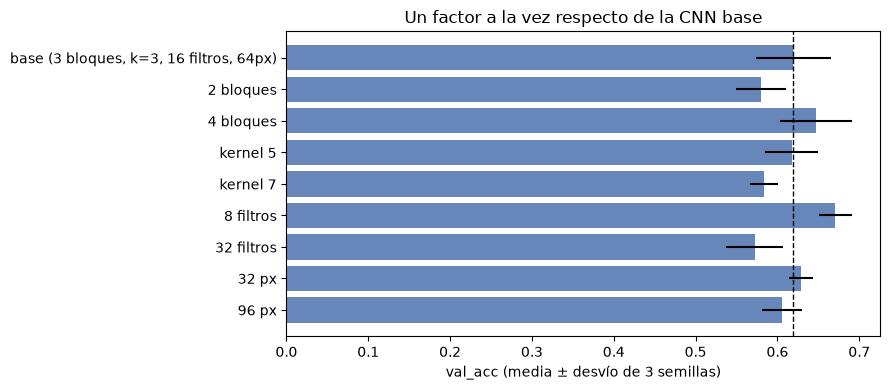

In [13]:
ARCH_VARIANTS = {
    "base (3 bloques, k=3, 16 filtros, 64px)": {},
    "2 bloques": dict(n_blocks=2), "4 bloques": dict(n_blocks=4),
    "kernel 5": dict(kernel=5), "kernel 7": dict(kernel=7),
    "8 filtros": dict(filters=8), "32 filtros": dict(filters=32),
    "32 px": dict(size=32), "96 px": dict(size=96),
}
rows, arch_cfgs, arch_hist = [], {}, {}
for name, delta in ARCH_VARIANTS.items():
    cfg = {**BASE, **delta}; r, ms, hs = run(cfg)
    rows.append(dict(variante=name, campo_receptivo=rf_full(cfg["n_blocks"], cfg["kernel"]), **r)); arch_cfgs[name] = cfg; arch_hist[name] = hs[0]
tab_arch = pd.DataFrame(rows)
display(tab_arch[["variante", "campo_receptivo", "params", "val_acc", "val_acc_std", "train_acc", "brecha", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(tab_arch["variante"], tab_arch["val_acc"], xerr=tab_arch["val_acc_std"], color="#4c72b0", alpha=.85); ax.invert_yaxis()
ax.axvline(tab_arch["val_acc"].iloc[0], color="k", ls="--", lw=1); ax.set_xlabel("val_acc (media ± desvío de 3 semillas)"); ax.set_title("Un factor a la vez respecto de la CNN base"); plt.tight_layout(); plt.show()

### ✏️ TU ANÁLISIS 2 - Arquitectura convolucional
1. ¿Qué factores cambian la val_acc **más allá del ruido entre semillas** (desvío de la tabla) y cuáles no? Sean explícitos sobre qué diferencias son pequeñas respecto del ruido.
2. **Profundidad y kernel:** relacionen el campo receptivo con el tamaño de la imagen y con lo que se quiere detectar en una lesión (bordes, texturas, asimetría global). ¿Qué esperaban de agregar bloques o agrandar el kernel y qué se observó? Comparen costo (parámetros y tiempo) vs. ganancia.
3. **Resolución de entrada (32/64/96):** ¿cómo cambia la cantidad de parámetros de la capa `Linear` de la cabeza y por qué? ¿Qué se gana (detalle disponible) y qué se pierde (cómputo, campo receptivo relativo a la imagen)? Con tan pocas imágenes por clase, ¿qué límite tiene este experimento?
4. ¿Qué no se puede concluir con un diseño de "un factor a la vez" y 3 semillas?

1. **Comparación de arquitecturas**

La configuración base obtiene un accuracy de 0.619 ± 0.046. La mayoría de las variaciones (kernel, resolución y cantidad de bloques) presentan diferencias pequeñas, que pueden deberse al azar.

La diferencia más importante aparece entre 8 y 32 filtros (0.671 y 0.572). Sin embargo, esto podría deberse a que el learning rate y el early stopping no son los más adecuados para todas las arquitecturas.

2. **Campo receptivo**

El campo receptivo indica qué parte de la imagen puede analizar una neurona. Para reconocer características locales, como bordes y texturas, alcanza con un campo chico. En cambio, para identificar características globales de la lesión, conviene uno más grande.

Los resultados muestran que usar 4 bloques mejora el campo receptivo y reduce los parámetros (361 k). En cambio, usar 2 bloques deja un campo pequeño y necesita más parámetros (1,05 M).

Por lo tanto, aumentar la profundidad puede ser conveniente que utilizar kernels más grandes.

3. **Efecto de la resolución**

Al aumentar la resolución, también aumenta mucho la cantidad de parámetros de la capa final. Por ejemplo, pasa de 131 k parámetros con 32 px a 524 k con 64 px y 1,18 M con 96 px.

Aunque una mayor resolución permite conservar más detalles, también aumenta el computo y el riesgo de sobreajuste. Los resultados obtenidos (0.629, 0.619 y 0.606) son muy similares, por lo que no se observa una mejora clara al aumentar la resolución.

4. **Interacciones y limitaciones**

Como se cambia un factor a la vez, no se pueden ver las interacciones entre ellos: por ejemplo, combinar 4 bloques con 8 filtros no tiene por qué sumar ambas mejoras.
Además, se usaron pocas semillas, una sola partición de datos y una validación chica, así que no se puede asegurar que una arquitectura sea mejor que otra.
Por último, elegir la mejor configuración entre muchas pruebas puede favorecer resultados que simplemente se dieron por azar.

## 7. Data augmentation
Con ~60 imágenes por clase en train, el overfitting es esperable. Se comparan cuatro niveles de augmentation (los de la sección 3) con la CNN base y 3 semillas. En cada caso, **train queda con las imágenes originales más `AUG_COPIES` copias aumentadas de cada una**; val y test no se tocan.

,augmentation,n_train,val_acc,val_acc_std,train_acc,brecha,val_loss,best_epoch,t_epoca_s,t_total_s
0,ninguna,506,0.6193,0.0477,0.8017,0.1824,1.0403,10.3333,0.0363,0.7396
1,flips,1518,0.6036,0.0048,0.8505,0.2469,1.0730,10.0000,0.1038,2.0766
2,flips+rot90,1518,0.6647,0.0218,0.8808,0.2161,1.0670,14.3333,0.1039,2.5261
3,flips+rot90+color,1518,0.6292,0.0489,0.7819,0.1528,1.0320,8.6667,0.1050,1.9605


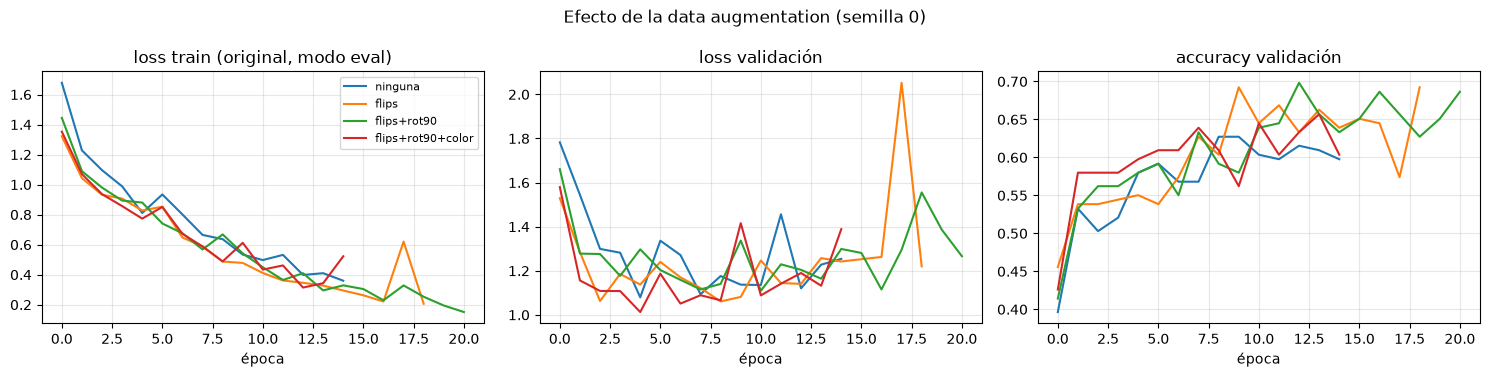

In [14]:
rows, aug_hist = [], {}
for name in AUGS:
    cfg = {**BASE, "aug": name}; r, ms, hs = run(cfg)
    rows.append(dict(augmentation=name, n_train=len(train_set(64, name)[0]), **r)); aug_hist[name] = hs[0]
tab_aug = pd.DataFrame(rows)
display(tab_aug[["augmentation", "n_train", "val_acc", "val_acc_std", "train_acc", "brecha", "val_loss", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
plot_curves(aug_hist, "Efecto de la data augmentation (semilla 0)")

### ✏️ TU ANÁLISIS 3 - Overfitting y augmentation
1. Demostrá el overfitting de la CNN sin augmentation **con números**: brecha train-val, época donde la `val_loss` empieza a subir.
2. ¿Qué cambia con cada nivel de augmentation sobre la **brecha**, la `val_loss`, la `val_acc`, la **época de convergencia** y el **tiempo total**? ¿Por qué cada época cuesta más con augmentation? ¿Cuál de las mejoras supera el ruido entre semillas?
3. Discutan desde el dominio (dermatología) qué transformaciones tienen sentido y cuáles podrían **destruir información** (por ejemplo, el color o la escala). ¿Qué otras augmentations probarían?
4. ¿Por qué es importante que la augmentation se haga **después** del split y **solo en train**? ¿Qué pasaría con las métricas si se aumentara antes de dividir?
5. Compará con lo que vieron en el TP3: ¿qué diferencia hay entre regularizar con dropout/L2 (restricciones sobre los pesos) y con augmentation (más datos sintéticos)?

1. **Sobreajuste sin augmentation**

Sin augmentation, el modelo obtiene una accuracy de 0.802 en entrenamiento y 0.619 en validación. Esta diferencia muestra un claro sobreajuste.

Además, la pérdida de validación comienza a aumentar aproximadamente desde la época 5 (en la semilla 0), mientras que la de entrenamiento sigue disminuyendo. Esto indica que el modelo aprende cada vez mejor las imágenes de entrenamiento, pero no logra generalizar correctamente.

2. **Comparación de augmentation**

Los resultados obtenidos son:

| Augmentation | Val accuracy | Brecha |
|---|---:|---:|
| Ninguna | 0.619 | 0.182 |
| Flips | 0.604 | 0.247 |
| Flips + rotaciones | 0.665 | 0.216 |
| Flips + rotaciones + color | 0.629 | 0.153 |

La combinación de flips y rotaciones obtiene la mayor accuracy, aunque la mejora no es suficientemente grande como para asegurar que sea significativa.

Por otro lado, solamente los cambios de color reducen la brecha entre entrenamiento y validación. Esto muestra que no todas las técnicas de augmentation ayudan de la misma manera.

El entrenamiento también tarda más porque aumenta la cantidad de imágenes procesadas por época.

3. **¿Qué augmentation conviene utilizar?**

Las lesiones no tienen una orientación específica, por lo que los flips y las rotaciones son transformaciones adecuadas.

En cambio, hay que tener cuidado con los cambios de color, porque pueden modificar características importantes para el diagnóstico. También hay que evitar recortes agresivos que puedan eliminar partes de la lesión.

Otras opciones posibles son pequeñas variaciones de brillo, rotaciones suaves, blur y compresión JPEG.

4. **¿Por qué aplicar augmentation después del split?**

La augmentation debe realizarse después de separar los datos en entrenamiento, validación y prueba.

Si se realiza antes, una imagen original podría quedar en entrenamiento y una versión modificada en validación o prueba. Esto produciría una fuga de información y resultados artificialmente mejores.

Además, validación y prueba deben contener imágenes reales, sin modificaciones artificiales.

5. **Augmentation frente a dropout y L2**

El dropout y L2 ayudan a evitar el sobreajuste limitando el comportamiento del modelo.

En cambio, augmentation agrega variedad a los datos de entrenamiento y enseña al modelo qué características no deberían afectar la clasificación, como la orientación de una lesión.

Ambas técnicas son complementarias, pero augmentation solo es útil si las transformaciones mantienen las características importantes de las imágenes.

## 8. Elección del modelo final y evaluación en TEST (una sola vez)
Se arma la configuración final tomando, entre las variantes de arquitectura, la de **mejor val_acc media** y, entre las de augmentation, la de **mejor val_acc media** (ambas ya medidas arriba). Se puede forzar otra decisión con `FINAL_OVERRIDE` (justificándola en el análisis). Es una decisión *greedy* de un factor a la vez: no se garantiza que la combinación sea mejor que cada parte.

Luego se entrenan la config final y la MLP de referencia (64 px) con las semillas `SEEDS_FINAL` y se evalúan en test **una única vez**. No se vuelve a tocar nada después de ver estos números.

In [15]:
best_arch = tab_arch.sort_values(["val_acc", "params"], ascending=[False, True]).iloc[0]["variante"]
best_aug  = tab_aug.sort_values("val_acc", ascending=False).iloc[0]["augmentation"]
FINAL_CFG = {**arch_cfgs[best_arch], "aug": best_aug}
FINAL_OVERRIDE = None          # por ejemplo: dict(n_blocks=4, aug="flips+rot90")
if FINAL_OVERRIDE: FINAL_CFG = {**FINAL_CFG, **FINAL_OVERRIDE}
print("Mejor arquitectura (val):", best_arch, "| mejor augmentation (val):", best_aug)
print("Config final:", FINAL_CFG)
rf_, ms_, hs_ = run(FINAL_CFG)
print(f"Config final en validación: val_acc {rf_['val_acc']:.3f} ± {rf_['val_acc_std']:.3f} | brecha {rf_['brecha']:.3f} | mejor época {rf_['best_epoch']:.1f} | {rf_['t_total_s']:.0f}s por entrenamiento")

Mejor arquitectura (val): 8 filtros | mejor augmentation (val): flips+rot90
Config final: {'model': 'cnn', 'size': 64, 'n_blocks': 3, 'filters': 8, 'kernel': 3, 'dropout': 0.2, 'lr': 0.003, 'aug': 'flips+rot90'}
Config final en validación: val_acc 0.647 ± 0.039 | brecha 0.177 | mejor época 7.7 | 2s por entrenamiento


,modelo,params,test_acc,test_acc_std,test_f1_macro,f1_std,tiempo_entrenamiento_s
0,CNN final,269521,0.6722,0.0247,0.6622,0.0276,2.0021
1,MLP 64px,6358793,0.4793,0.0365,0.4574,0.0425,0.4382


Error estándar binomial del test (169 imágenes): ±0.036 | azar: 0.111
                            precision    recall  f1-score   support

         Actinic keratosis       0.53      0.45      0.49        20
         Atopic Dermatitis       0.84      1.00      0.91        16
          Benign keratosis       0.86      0.95      0.90        20
            Dermatofibroma       0.60      0.60      0.60        20
         Melanocytic nevus       0.70      0.70      0.70        20
                  Melanoma       0.57      0.40      0.47        20
   Squamous cell carcinoma       0.50      0.65      0.57        20
Tinea Ringworm Candidiasis       0.78      0.54      0.64        13
           Vascular lesion       0.82      0.90      0.86        20

                  accuracy                           0.69       169
                 macro avg       0.69      0.69      0.68       169
              weighted avg       0.68      0.69      0.68       169



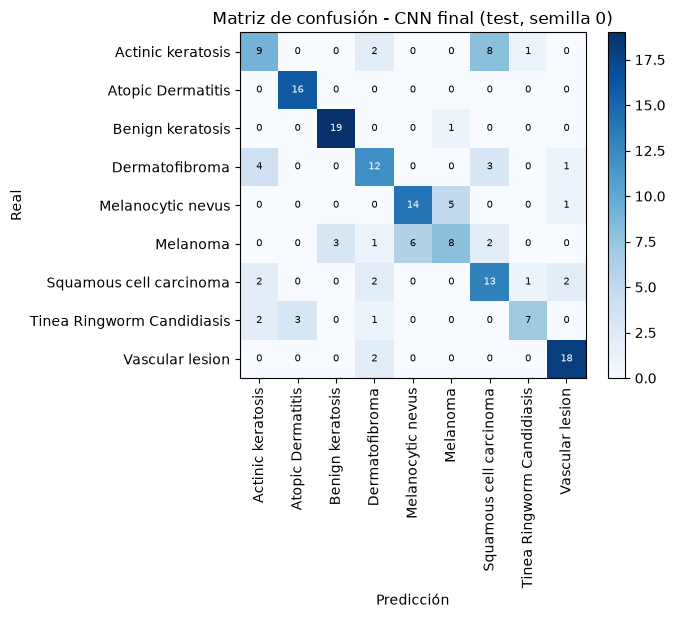

In [16]:
# ---- EVALUACIÓN EN TEST: se ejecuta una sola vez ----
final_rows, final_models, final_preds = [], {}, {}
for name, cfg in [("CNN final", FINAL_CFG), ("MLP 64px", {**BASE, "model": "mlp", "size": 64})]:
    accs, f1s, times = [], [], []
    for s in SEEDS_FINAL:
        m, h = fit(cfg, s); _, a, p = evaluate(m, idx_te, cfg["size"])
        accs.append(a); f1s.append(f1_score(labels[idx_te], p, average="macro")); times.append(sum(h["epoch_time"]))
        if s == SEEDS_FINAL[0]: final_models[name], final_preds[name] = m, p
    final_rows.append(dict(modelo=name, params=h["n_params"], test_acc=np.mean(accs), test_acc_std=np.std(accs), test_f1_macro=np.mean(f1s), f1_std=np.std(f1s), tiempo_entrenamiento_s=np.mean(times)))
final = pd.DataFrame(final_rows); display(final.round(4))
se = np.sqrt(final.loc[0, "test_acc"] * (1 - final.loc[0, "test_acc"]) / len(idx_te))
print(f"Error estándar binomial del test ({len(idx_te)} imágenes): ±{se:.3f} | azar: {1/NUM_CLASSES:.3f}")
p = final_preds["CNN final"]
print(classification_report(labels[idx_te], p, target_names=class_names, zero_division=0))
cm = confusion_matrix(labels[idx_te], p)
plt.figure(figsize=(7, 6)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90); plt.yticks(range(NUM_CLASSES), class_names)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES): plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title(f"Matriz de confusión - CNN final (test, semilla {SEEDS_FINAL[0]})"); plt.tight_layout(); plt.show()

## 9. ¿Qué aprende la red?
Se muestran (sobre imágenes de **validación**, no de test): los filtros de la primera convolución, los **mapas de activación** de la primera y la última capa convolucional para una imagen, y una galería de imágenes **mal clasificadas**.

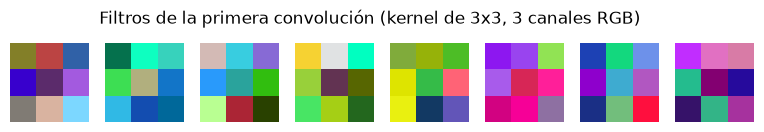

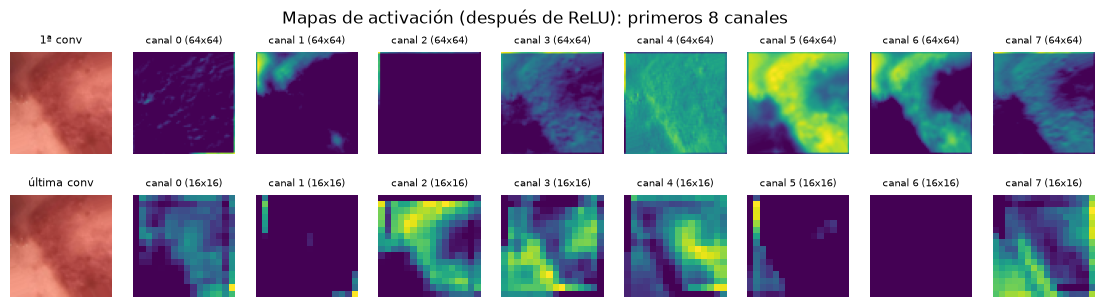

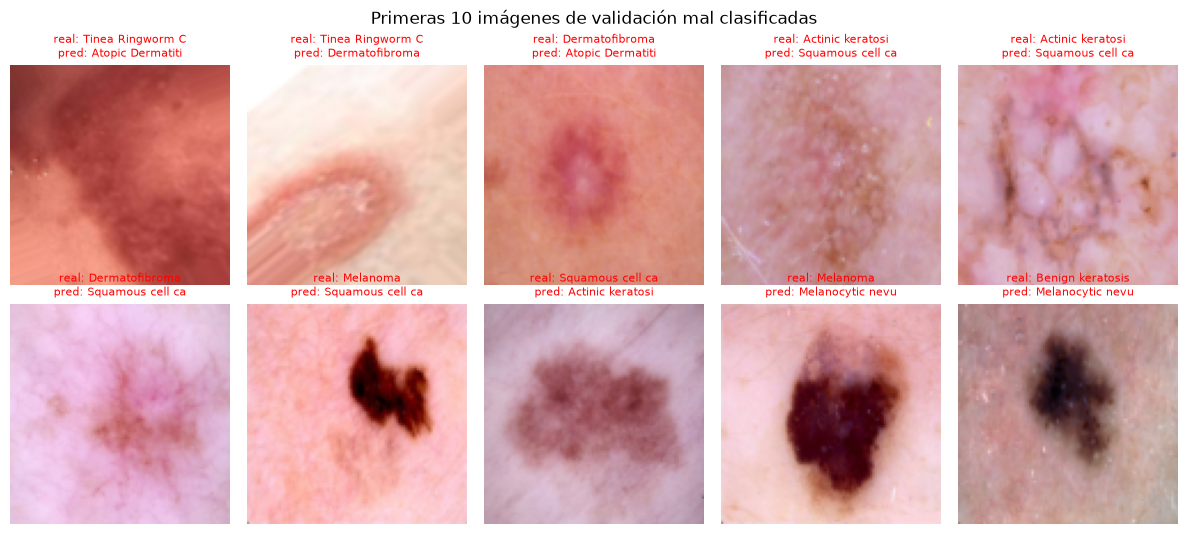

In [17]:
model = final_models["CNN final"].eval(); size = FINAL_CFG["size"]
W = model.features[0].weight.detach().cpu(); n = min(W.shape[0], 16)
fig, ax = plt.subplots(1, n, figsize=(1.2 * n, 1.5))
for i in range(n):
    w = W[i]; w = (w - w.min()) / (w.max() - w.min() + 1e-8); ax[i].imshow(w.permute(1, 2, 0), interpolation="nearest"); ax[i].axis("off")
fig.suptitle("Filtros de la primera convolución (kernel de %dx%d, 3 canales RGB)" % (W.shape[2], W.shape[3])); plt.show()

relu_pos = [i for i, l in enumerate(model.features) if isinstance(l, nn.ReLU)]
xi, yi = get_eval_batch(size, idx_va[:1])
with torch.no_grad(): a_first = model.features[:relu_pos[0] + 1](xi)[0].cpu(); a_last = model.features[:relu_pos[-1] + 1](xi)[0].cpu()
fig, ax = plt.subplots(2, 9, figsize=(14, 3.4))
for r_, (a, nm) in enumerate([(a_first, "1ª conv"), (a_last, "última conv")]):
    ax[r_, 0].imshow(X_U8[size][idx_va[0]].permute(1, 2, 0)); ax[r_, 0].set_title(nm, fontsize=8); ax[r_, 0].axis("off")
    for k in range(8): ax[r_, k + 1].imshow(a[k], cmap="viridis"); ax[r_, k + 1].axis("off"); ax[r_, k + 1].set_title(f"canal {k} ({a.shape[1]}x{a.shape[2]})", fontsize=7)
plt.suptitle("Mapas de activación (después de ReLU): primeros 8 canales"); plt.show()

_, _, pv = evaluate(model, idx_va, size)
bad = [i for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]; pbad = [p_ for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]
fig, ax = plt.subplots(2, 5, figsize=(12, 5.4))
for a, i, pr in zip(ax.flat, bad, pbad):
    a.imshow(X_U8[96][i].permute(1, 2, 0)); a.axis("off"); a.set_title(f"real: {class_names[labels[i]][:16]}\npred: {class_names[pr][:16]}", fontsize=8, color="red")
plt.suptitle("Primeras 10 imágenes de validación mal clasificadas"); plt.tight_layout(); plt.show()

### ✏️ TU ANÁLISIS 4 - Resultados finales e interpretación
1. **Consistencia val vs. test:** ¿el resultado de test es coherente con la validación? Tengan en cuenta el error estándar binomial del test y que elegimos el mejor entre varias configuraciones sobre validación (sesgo optimista).
2. **CNN vs. MLP en test:** ¿la diferencia supera el ruido entre semillas (± desvío) y el error estándar del test? ¿Se justifica el costo en parámetros/tiempo?
3. **Matriz de confusión y reporte por clase:** ¿qué clases se confunden más y por qué (similitud clínica/visual)? En este problema, ¿es igual de grave confundir cualquier par de clases? ¿Qué métrica (recall de melanoma, F1 macro, otra) les parece más relevante que el accuracy y por qué?
4. **Filtros, mapas de activación y errores:** ¿qué detectan las primeras capas y qué cambia en la última (tamaño espacial, nivel de abstracción)? ¿Qué patrones comunes tienen las imágenes mal clasificadas?
5. **Sesgos y limitaciones:** retomen el EDA (resoluciones y color por clase, duplicados). ¿Qué sesgos del dataset podrían inflar o distorsionar los números? Tamaño del dataset, una sola partición, pocas semillas, validación chica: ¿qué harían con más tiempo?

1. **Resultados del modelo final**

La configuración final (8 filtros + flips y rotaciones) obtiene un accuracy de 0.647 ± 0.039 en validación y 0.672 ± 0.025 en test, con un F1 macro de 0.662.

Los resultados de validación y test son coherentes. Sin embargo, combinar las dos mejoras no produjo un resultado superior al de cada una por separado.

2. **Comparación entre CNN y MLP**

La CNN obtiene un accuracy de 0.672 ± 0.025, mientras que la MLP alcanza 0.479 ± 0.037. La diferencia (+0.19) es mucho mayor que el desvío entre semillas y que el error estándar del test (±0.036), así que supera claramente el ruido.

Además, la CNN utiliza 23,6 veces menos parámetros (270 k frente a 6,36 M). Aunque tarda más en entrenar, consigue mejores resultados con un modelo mucho más pequeño.


3. **Errores de clasificación**

Los errores más frecuentes aparecen entre melanoma y nevus, y entre queratosis actínica (QA) y carcinoma escamocelular (SCC), ya que son lesiones que pueden tener características visuales similares.

El más preocupante es la clasificación de melanomas como lesiones benignas: de los 20 melanomas, 12 fueron mal clasificados, y 10 de ellos como lesiones benignas.

Por eso, en este problema no alcanza con evaluar solamente el accuracy. También es importante el recall de melanoma, ya que permite medir cuántos casos de esta enfermedad logra detectar el modelo.

4. **Interpretación de los filtros**

Las primeras capas de la CNN detectan principalmente colores, contrastes y bordes. Las últimas capas combinan esas características para reconocer regiones más complejas de las lesiones.

Los errores aparecen principalmente en lesiones con poco contraste, bordes difusos o colores similares. Esto sugiere que algunos detalles importantes se pierden durante el procesamiento de las imágenes.

5. **Limitaciones del dataset y posibles mejoras**

Se observó que muchas imágenes tienen resoluciones diferentes según su clase de origen. Esto puede provocar que el modelo aprenda características de la fuente de las imágenes en lugar de reconocer solamente las lesiones.

Además, el dataset es pequeño (aproximadamente 60 imágenes por clase), por lo que los resultados todavía tienen limitaciones.

Para mejorar el trabajo, sería conveniente utilizar más imágenes, aplicar validación cruzada, probar transfer learning y utilizar Grad-CAM para entender qué regiones de las imágenes utiliza el modelo.

También sería importante priorizar la detección de melanomas y evaluar el modelo con un conjunto de imágenes externas.

## Declaración de uso de IA
Completen (obligatorio): ¿usaron herramientas de IA? ¿Cuáles, para qué parte (código, redacción del análisis, ideas) y qué modificaron o verificaron por su cuenta? Si no usaron, aclaren que no.

Use claude para mejorar un poco la redaccion de mis ideas, pero no para hacer el analisis.
